# Model Results, Limitations, and Project Conclusions
## tl;dr
The current conclusions use the real-data benchmark from notebook 4. The original notebook 5 generated random features and random labels; its ROC-AUC values of approximately 0.45 and 0.47 are **not traffic-data results**. The historical 96.8% accuracy also lacked an adequate majority baseline and accident-class evaluation. Neither supports a claim of validated crash prediction.

Verified run: 200,000 sampled stops, including 39,967 in the chronological test set. The validation-selected histogram boosting model achieved test ROC-AUC **0.667** and average precision **0.036**, versus the constant-score AP baseline of **0.020**. At the validation-selected threshold, accident precision was **4.42%** and recall **8.86%**. These results show limited ranking signal and weak practical detection, not deployment readiness.

## Context & Methods
This notebook reads aggregate outputs from the reproducible run, not manually transcribed performance claims. The original notebooks are preserved in a local, Git-ignored coursework archive. The revised analysis uses a larger raw CSV, a different feature set, one row per eligible stop, and chronological evaluation; direct numerical before/after comparisons with the old random split would be misleading.

In [1]:
from pathlib import Path
import sys
ROOT = next((candidate for candidate in [Path.cwd(), *Path.cwd().parents]
             if (candidate / "src/traffic_analysis.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the traffic project repository.")
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 15)

## Data

In [2]:
import json
from IPython.display import Image
metrics_path = ROOT / "reports/test_metrics.csv"
if not metrics_path.exists():
    raise FileNotFoundError("Run notebook 4 or python scripts/run_analysis.py first.")
metrics = pd.read_csv(metrics_path)
model_run = json.loads((ROOT / "reports/model_run.json").read_text())
display(pd.DataFrame(model_run["partitions"]).T)
display(metrics[["model", "accuracy", "balanced_accuracy", "accident_precision", "accident_recall", "accident_f1", "roc_auc", "average_precision"]].round(4))

,stops,positive_stops,positive_rate,date_min,date_max
train,120020,1997,0.016639,2012-01-01,2017-09-12
validation,40013,578,0.014445,2017-09-13,2019-08-02
test,39967,801,0.020042,2019-08-03,2024-09-16


,model,accuracy,balanced_accuracy,accident_precision,accident_recall,accident_f1,roc_auc,average_precision
0,Majority baseline,0.9800,0.5000,0.0000,0.0000,0.0000,0.5000,0.0200
1,Single-tree benchmark,0.9800,0.5000,0.0000,0.0000,0.0000,0.6129,0.0304
2,Balanced logistic regression,0.6205,0.6009,0.0304,0.5805,0.0578,0.6460,0.0355
3,Balanced random forest,0.7120,0.5993,0.0336,0.4819,0.0629,0.6651,0.0349
4,Balanced histogram boosting,0.6188,0.6202,0.0323,0.6217,0.0614,0.6674,0.0362
5,Balanced histogram boosting (validation thresh...,0.9434,0.5247,0.0442,0.0886,0.0590,0.6674,0.0362


## Results
The following statements are computed from the actual held-out results. The validation-selected threshold raises precision but sharply reduces test recall relative to threshold 0.5. This trade-off does not establish operational usefulness.

Majority baseline: accuracy=97.996%, accident recall=0.000%.
Validation-selected model: Balanced histogram boosting.
Held-out ROC-AUC=0.667; average precision=0.036.
Positive prevalence / constant-score AP baseline=2.004%.
At the validation-selected threshold: precision=4.424%, recall=8.864%, F1=0.059.
Confusion counts: TP=71, FP=1,534, FN=730, TN=37,632.


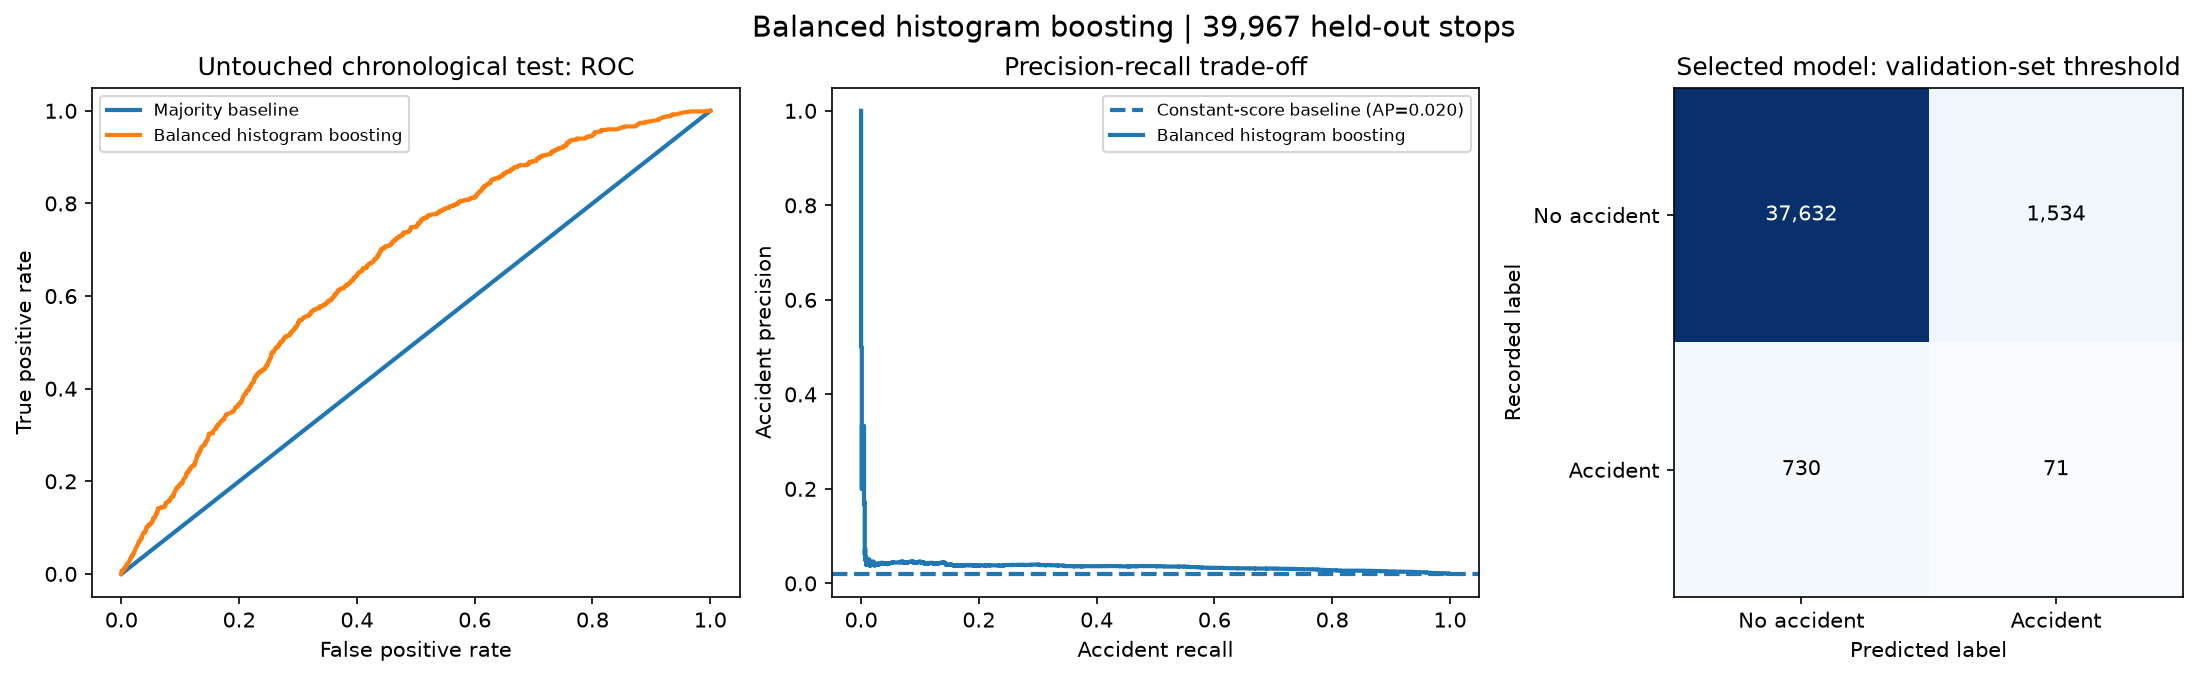

In [3]:
baseline = metrics.loc[metrics.model.eq("Majority baseline")].iloc[0]
selected = metrics.loc[metrics.model.eq(model_run["selected_model"])].iloc[0]
tuned = metrics.iloc[-1]
print(f"Majority baseline: accuracy={baseline.accuracy:.3%}, accident recall={baseline.accident_recall:.3%}.")
print(f"Validation-selected model: {model_run['selected_model']}.")
print(f"Held-out ROC-AUC={selected.roc_auc:.3f}; average precision={selected.average_precision:.3f}.")
print(f"Positive prevalence / constant-score AP baseline={model_run['partitions']['test']['positive_rate']:.3%}.")
print(f"At the validation-selected threshold: precision={tuned.accident_precision:.3%}, recall={tuned.accident_recall:.3%}, F1={tuned.accident_f1:.3f}.")
print(f"Confusion counts: TP={int(tuned.tp):,}, FP={int(tuned.fp):,}, FN={int(tuned.fn):,}, TN={int(tuned.tn):,}.")
display(Image(filename=str(ROOT / "assets/model-evaluation.png")))

## Takeaways
The project demonstrates source validation, chunked preparation, record-grain reasoning, reproducible EDA, and honest evaluation under class imbalance. It does not establish a causal relationship between an infraction and a crash, validate statewide generalization, or justify targeting individual drivers or demographic groups.

Further work would include validating predictor availability at the intended decision time, an independent external snapshot, calibration checks, and a documented cost-based decision threshold. Repeated test-set tuning would require a fresh final holdout. The static input hash and software versions are stored in `reports/` so another reader can identify the evaluated run.